# Part 2 · Article classification
Case deliverables: *find relevant features for inventory article classification · apply a data science approach to classify the articles ·
recommend strategies per class and define which class(es) should be taken on stock.*

Pipeline: **1** population & features → **2** feature selection (redundancy filter + domain screen + set comparison) → **3** algorithm & k selection
(K-means vs Gaussian mixture vs Ward; silhouette, Davies–Bouldin, Calinski–Harabasz) → **4** stability (bootstrap ARI) → **5** profiles, ABC-XYZ benchmark
and feature relevance → **6** strategies and stocking decision → **7** export per article.

In [1]:
import sys, warnings; sys.path[:0] = ['..', '../..']; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from shared.prep import load_transactions, article_master, daily_inventory, END
from src.classify import *
pd.set_option('display.float_format', '{:,.3f}'.format); pd.set_option('display.width', 200)
BLUE, LBLUE, GREY, SAND, NAVY, ORANGE = '#2a78d6', '#7fb0ea', '#a3a9b1', '#d9d5cc', '#13294b', '#d9541e'
COL = {'Runners': BLUE, 'Repeaters': LBLUE, 'One-offs': GREY, 'Dormant': SAND}
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True,
                     'grid.color': '#e6e2da', 'axes.edgecolor': '#b5b4ad', 'font.size': 10, 'axes.titleweight': 'bold'})
FIG = '../outputs/figures'; save = lambda n: plt.savefig(f'{FIG}/{n}.png', bbox_inches='tight')
tx = load_transactions(); art = article_master(tx)
S36 = END - pd.DateOffset(years=3)

## 1 · Population and candidate features
Population: every article with at least one sale or production use in the last 36 months (**active articles**), stocked or not,
because the question is *which* articles belong on stock.

In [2]:
F = article_features(tx, art, S36, END)
X = model_matrix(F)
print(f'{len(F):,} active articles · {F.stocked_now.sum():,} currently stocked · {X.shape[1]} candidate features')
X.describe().T[['mean', '50%', 'std']]

20,890 active articles · 1,499 currently stocked · 12 candidate features


,mean,50%,std
log_usage_value,5.179,5.047,1.743
weeks_with_demand,1.253,0.693,0.961
cv2_size,0.201,0.000,0.367
recency_days,443.026,380.000,340.324
log_demand_lines,0.782,0.288,0.961
cv_weekly,10.162,12.530,3.350
trend,0.034,0.000,1.274
log_price,4.321,4.684,1.773
lead_time,6.241,0.000,14.407
production_share,0.093,0.000,0.283


## 2 · Feature selection

Dropped as redundant (|Spearman ρ| > 0.85): ['cv_weekly', 'log_demand_lines']
ρ(weeks with demand, cv²) = 0.90 overall, 0.49 for articles with ≥ 3 demand weeks → kept (artefact of cv² = 0 for one-time demand)


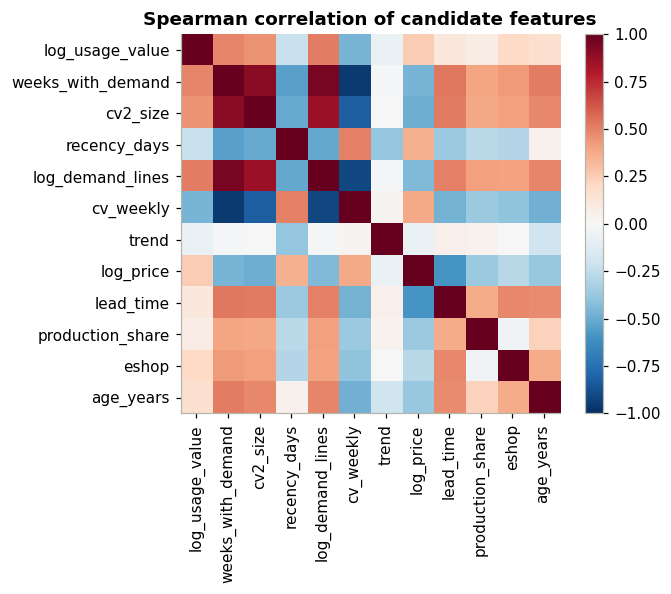

In [3]:
keep, drop, Cm = redundancy_filter(X)
print('Dropped as redundant (|Spearman ρ| > 0.85):', drop)
m = F.weeks_with_demand_share * 157 >= 3
print(f"ρ(weeks with demand, cv²) = {Cm.loc['weeks_with_demand','cv2_size']:.2f} overall, "
      f"{X[m][['weeks_with_demand','cv2_size']].corr('spearman').iloc[0,1]:.2f} for articles with ≥ 3 demand weeks → kept (artefact of cv² = 0 for one-time demand)")
fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.imshow(X.corr(method='spearman'), cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(X.shape[1])); ax.set_xticklabels(X.columns, rotation=90); ax.set_yticks(range(X.shape[1])); ax.set_yticklabels(X.columns)
ax.grid(False); plt.colorbar(im, fraction=.04); ax.set_title('Spearman correlation of candidate features'); plt.tight_layout(); save('p2_correlation'); plt.show()

**Domain screen of the remaining 10 → final 4**
| Feature | Decision | Reason |
|---|---|---|
| usage value | **keep** | the money a class represents (ABC idea) |
| weeks with demand | **keep** | how often an article is needed |
| order-size variability (cv²) | **keep** | how predictable demand is (XYZ idea) |
| recency | **keep** | whether the article is still alive |
| price | drop | already inside usage value |
| lead time | drop | maintained mainly for stocked articles → leaks today's decision |
| production share, e-shop, age | profile only | describe classes; binary/structural flags distort distances |
| trend | drop | noisy for low-volume articles |

In [4]:
SETS = {'value + frequency + variability + recency (final)': FINAL_FEATURES,
        '+ price': FINAL_FEATURES + ['log_price'],
        '+ production share': FINAL_FEATURES + ['production_share'],
        'all 10 after filter': keep}
rows = []
for name, cols in SETS.items():
    Z_ = StandardScaler().fit_transform(X[cols])
    for k in (3, 4, 5):
        rows.append(dict(feature_set=name, k=k, **evaluate(Z_, KMeans(k, n_init=10, random_state=0).fit(Z_).labels_)))
fs = pd.DataFrame(rows); fs.pivot(index='feature_set', columns='k', values='silhouette')

k,3,4,5
feature_set,,,
+ price,0.295,0.290,0.284
+ production share,0.462,0.346,0.357
all 10 after filter,0.229,0.249,0.260
value + frequency + variability + recency (final),0.348,0.341,0.302


Adding price or all 10 filtered features lowers cluster quality; production share scores about the same at k = 4 but splits by product type rather than demand behaviour, so it is used for profiling only. Pure silhouette maximisation (tested) keeps the binary e-shop flag and
drops usage value, producing trivial splits, so selection combines statistics with domain relevance.

## 3 · Algorithm and number of classes

In [5]:
Z, km = fit_final(X)
alg = compare_algorithms(Z)
alg.pivot(index='algorithm', columns='k', values=['silhouette', 'davies_bouldin'])

silhouette             davies_bouldin            
k                                        3     4     5              3     4     5
algorithm                                                                        
Agglomerative (Ward, 8k sample)      0.270 0.268 0.243          1.033 1.330 1.339
Gaussian mixture                     0.130 0.058 0.055          2.172 2.401 3.183
K-means                              0.348 0.341 0.302          1.016 1.125 1.151

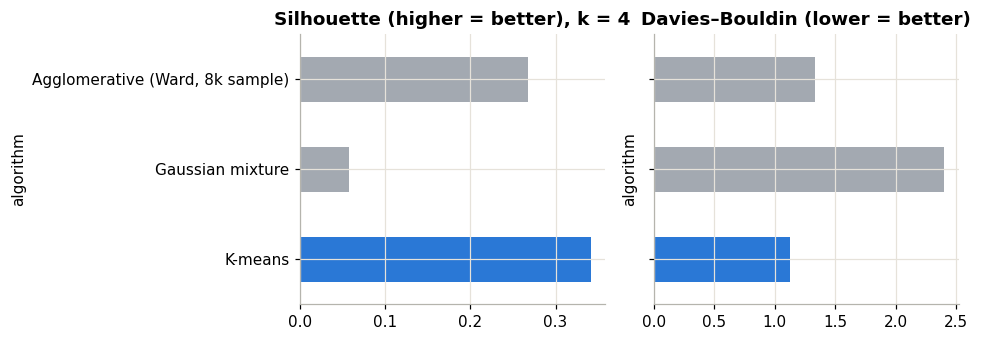

In [6]:
a4 = alg[alg.k == 4].set_index('algorithm')
fig, ax = plt.subplots(1, 2, figsize=(9, 3.2))
a4.silhouette.plot.barh(ax=ax[0], color=[BLUE if i == 'K-means' else GREY for i in a4.index]); ax[0].set_title('Silhouette (higher = better), k = 4')
a4.davies_bouldin.plot.barh(ax=ax[1], color=[BLUE if i == 'K-means' else GREY for i in a4.index]); ax[1].set_title('Davies–Bouldin (lower = better)')
ax[1].set_yticklabels([]); plt.tight_layout(); save('p2_algorithms'); plt.show()

K-means is best on every metric. k = 3 scores marginally higher, but merges frequent and occasional articles that need different strategies;
**k = 4** keeps quality close to the best (silhouette 0.34, Davies–Bouldin 1.13) and gives four actionable classes.

## 4 · Stability

In [7]:
ari = bootstrap_stability(Z)
print(f'Bootstrap adjusted Rand index (20 refits): mean {ari.mean():.3f}, min {ari.min():.3f}')

Bootstrap adjusted Rand index (20 refits): mean 0.983, min 0.958


The classes are reproducible: refitting on resampled data reassigns almost no articles.

## 5 · Profiles, ABC-XYZ benchmark and feature relevance

In [8]:
names = name_clusters(F, km.labels_)
F['class'] = pd.Categorical(pd.Series(km.labels_, index=F.index).map(names), CLASS_ORDER)
S12 = END - pd.DateOffset(years=1) + pd.Timedelta(days=1); sv = {}
for ch in np.array_split(F.index.values, 20):
    e = daily_inventory(tx, ch).loc[S12:].fillna(0).mean(); sv.update((e * art.last_direct_cost.reindex(e.index)).to_dict())
F['avg_stock_value'] = pd.Series(sv).reindex(F.index).fillna(0)
prof = F.groupby('class', observed=False).agg(articles=('price', 'size'), usage_value=('annual_usage_value', 'sum'),
    orders_per_year=('n_demand_lines', 'median'), weeks_with_demand=('weeks_with_demand_share', 'median'), cv2=('cv2_size', 'median'),
    days_since_last=('days_since_last_demand', 'median'), price=('price', 'median'), production_share=('production_share', 'mean'),
    stocked_now=('stocked_now', 'sum'), stock_value=('avg_stock_value', 'sum'))
for c_ in ['articles', 'usage_value', 'stock_value']: prof[c_ + '_%'] = 100 * prof[c_] / prof[c_].sum()
prof.T

class,Runners,Repeaters,One-offs,Dormant
articles,"2,031.000","3,530.000","7,849.000","7,480.000"
usage_value,"21,672,251.606","4,119,339.527","1,239,987.882","2,316,552.665"
orders_per_year,16.996,2.000,0.333,0.333
weeks_with_demand,0.223,0.032,0.006,0.006
cv2,1.388,0.667,0.000,0.000
days_since_last,20.000,151.000,268.000,847.000
price,10.957,33.582,130.069,213.920
production_share,0.374,0.151,0.053,0.032
stocked_now,979.000,345.000,153.000,22.000
stock_value,"5,906,489.324","1,059,401.767","359,683.289","127,541.940"


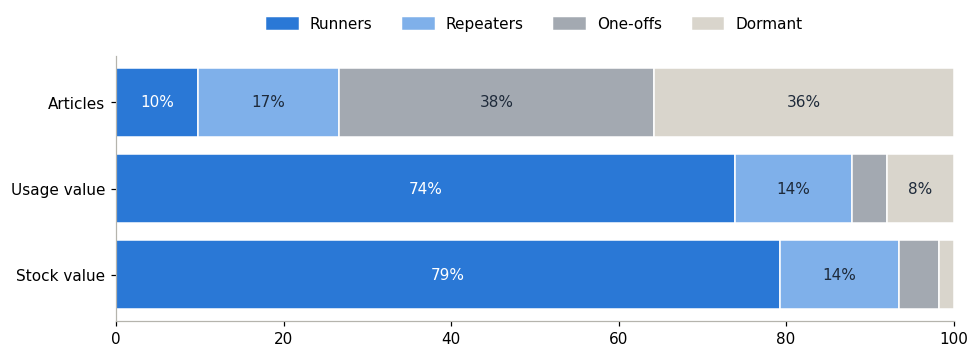

In [9]:
fig, ax = plt.subplots(figsize=(9, 3.4))
for j, col in enumerate(['articles_%', 'usage_value_%', 'stock_value_%']):
    left = 0
    for c_ in CLASS_ORDER:
        w = prof.loc[c_, col]; ax.barh(j, w, left=left, color=COL[c_], edgecolor='white')
        if w > 6: ax.text(left + w / 2, j, f'{w:.0f}%', ha='center', va='center', color='white' if c_ == 'Runners' else '#1e2a3a')
        left += w
ax.set_yticks(range(3)); ax.set_yticklabels(['Articles', 'Usage value', 'Stock value']); ax.invert_yaxis(); ax.set_xlim(0, 100); ax.grid(False)
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=COL[c_]) for c_ in CLASS_ORDER], labels=CLASS_ORDER, ncol=4, frameon=False, loc='upper center', bbox_to_anchor=(.5, 1.2))
plt.tight_layout(); save('p2_class_shares'); plt.show()

In [10]:
s = F.annual_usage_value.sort_values(ascending=False); cs = s.cumsum() / s.sum()
abc = pd.Series(np.select([cs <= .8, cs <= .95], ['A', 'B'], 'C'), index=s.index).reindex(F.index)
xyz = pd.cut(F.cv_weekly, [-1, 1, 2, 1e9], labels=['X', 'Y', 'Z'])
print('XYZ shares:', xyz.value_counts(normalize=True).round(3).to_dict())
pd.crosstab(F['class'], abc)

XYZ shares: {'Z': 0.977, 'Y': 0.019, 'X': 0.004}


col_0,A,B,C
class,,,
Runners,1063,791,177
Repeaters,334,1931,1265
One-offs,15,974,6860
Dormant,97,1644,5739


**Benchmark:** classic XYZ on weekly CV puts ~98% of articles into Z, so ABC-XYZ cannot separate this range. The clusters add frequency and recency:
most A-articles are Runners, but Runners also contain cheap, frequently used B/C items, and many B-articles turn out to be Dormant.

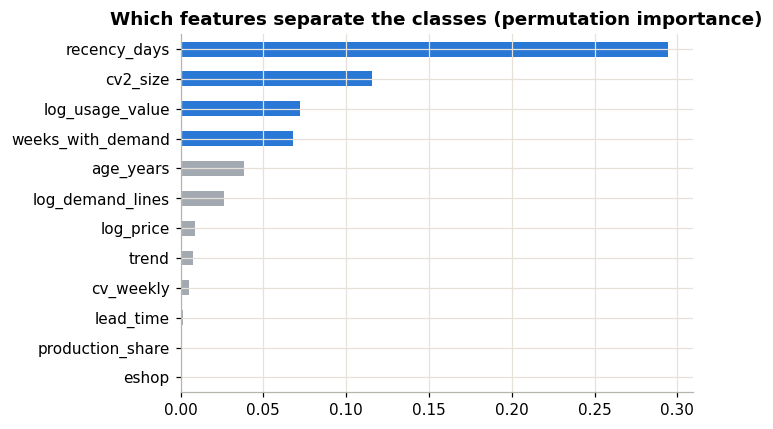

recency_days        0.294
cv2_size            0.116
log_usage_value     0.072
weeks_with_demand   0.068
age_years           0.038
log_demand_lines    0.026
log_price           0.009
trend               0.007
cv_weekly           0.005
lead_time           0.001
production_share    0.001
eshop               0.001
dtype: float64

In [11]:
rf = RandomForestClassifier(300, min_samples_leaf=5, random_state=0, n_jobs=-1)
samp = np.random.RandomState(0).choice(len(X), 8000, replace=False)
rf.fit(X.iloc[samp], F['class'].iloc[samp].astype(str))
pi = permutation_importance(rf, X.iloc[samp], F['class'].iloc[samp].astype(str), n_repeats=5, random_state=0, n_jobs=-1)
fi = pd.Series(pi.importances_mean, index=X.columns).sort_values()
fig, ax = plt.subplots(figsize=(6.5, 4)); fi.plot.barh(ax=ax, color=[BLUE if v > .05 else GREY for v in fi.values])
ax.set_title('Which features separate the classes (permutation importance)'); plt.tight_layout(); save('p2_feature_relevance'); plt.show()
fi.sort_values(ascending=False).round(3)

## 6 · Strategies and stocking decision

In [12]:
F['strategy'] = F['class'].map(STRATEGY)
F['take_on_stock'] = F['class'].map({'Runners': 'Yes', 'Repeaters': 'Selective', 'One-offs': 'No', 'Dormant': 'No'})
never = art.index[art.inv_article].difference(F.index)          # stocked, no demand in 36 months
delist = F[(F.stocked_now == 1) & F['class'].isin(['One-offs', 'Dormant'])]
review = F[(F.stocked_now == 0) & (F['class'] == 'Runners')]
print(f'De-list from stock: {len(delist)} stocked One-offs/Dormant + {len(never)} stocked articles without any demand in 36 months = {len(delist) + len(never)}')
print(f'Review for stocking: {len(review)} Runners without a reorder point ({review.production_share.gt(.5).mean():.0%} mainly used in production)')
pd.DataFrame(STRATEGY.items(), columns=['class', 'strategy'])

De-list from stock: 175 stocked One-offs/Dormant + 252 stocked articles without any demand in 36 months = 427
Review for stocking: 1052 Runners without a reorder point (18% mainly used in production)


,class,strategy
0,Runners,"Stock · demand-driven reorder point (Part 3), ..."
1,Repeaters,Stock selectively (only where lead time > cust...
2,One-offs,Procure / produce to order · no safety stock
3,Dormant,Phase out · run down or sell remaining stock


## 7 · Export

In [13]:
out = F[['class', 'take_on_stock', 'strategy', 'stocked_now', 'annual_usage_value', 'n_demand_lines', 'weeks_with_demand_share',
         'cv2_size', 'days_since_last_demand', 'price', 'lead_time', 'production_share', 'avg_stock_value']].copy()
out.index.name = 'article_nr'
out.to_csv('../outputs/article_classes.csv')
prof.to_csv('../outputs/class_profiles.csv'); alg.to_csv('../outputs/algorithm_comparison.csv', index=False)
print(f'Wrote {len(out):,} articles → outputs/article_classes.csv (input for Part 3: article_nr → class)')

Wrote 20,890 articles → outputs/article_classes.csv (input for Part 3: article_nr → class)
